# SmartEgg · Clasificador de visión (huevo / objeto / vacío)

Modelo de visión por computadora del Proyecto 2. Clasifica cada foto de la bandeja de la incubadora en una de tres clases:

| Clase | Qué hay en la foto | Acción del sistema |
|---|---|---|
| `huevo` | uno o más huevos, sin nada más | operación normal |
| `objeto` | cualquier cosa que no sea huevo: mano, pluma, llave, celular… | **alarma y bloqueo del sistema** |
| `vacio` | la bandeja sin nada | operación normal |

**Técnica:** *transfer learning* con **MobileNetV2** preentrenada en ImageNet. La red ya sabe reconocer bordes, texturas y formas; solo se le enseña a distinguir nuestras tres clases. Es una red liviana (≈2.2 M de parámetros con la cabeza nueva), así que corre en la CPU del servidor en la nube sin GPU.

**Dataset propio:** fotos reales tomadas con la cámara fija sobre la bandeja, con distintas condiciones de luz (foco de la incubadora, luz del cuarto y penumbra), por tandas de 5 fotos. Incluye 50 fotos extra de objetos pequeños entre huevos con el foco encendido, el caso que más fallaba.

La lógica está en `smartegg_vision.py`; este notebook la ejecuta paso a paso y muestra los resultados.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import smartegg_vision as sv
import torch

sv.set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATASET = sv.DEFAULT_DATASET      # Proyecto_2_SmartEgg/dataset/{huevo,objeto,vacio}
EPOCAS_CABEZA = 8
EPOCAS_AJUSTE = 12
PARTICIONES = 5                   # validación cruzada por tandas
print("Dispositivo:", DEVICE)
print("Dataset:", DATASET)

Dispositivo: cpu
Dataset: /mnt/development/Proyectos/AYC2_G3/Proyecto_2_SmartEgg/dataset


## 1. Dataset y separación por tandas

Las 5 fotos de una tanda son casi idénticas. Si se reparten al azar, algunas quedan en entrenamiento y sus "gemelas" en prueba, y el modelo parece mejor de lo que es. Por eso las fotos se **agrupan por tanda** (fotos tomadas con menos de 2 s de diferencia) y **cada tanda completa va a un solo conjunto**.

Con pocas tandas por clase, un único conjunto de prueba depende mucho de qué tandas caen en él: una sola tanda difícil cambia el resultado unos 10 puntos. Por eso se usa **validación cruzada por tandas con 5 particiones**: las tandas de cada clase se reparten en 5 partes y se entrenan 5 modelos. En cada uno:

- **Prueba (≈20 %)**: una de las 5 partes, distinta en cada partición.
- **Validación (≈15 %)**: para elegir la mejor época y detener el entrenamiento.
- **Entrenamiento (el resto)**: con estas aprende el modelo.

Así **cada foto se evalúa exactamente una vez**, con un modelo que nunca la vio.

In [2]:
samples = sv.list_samples(DATASET)
splits = sv.kfold_splits(samples, PARTICIONES)
groups = {s.group for s in samples}
print(f"{len(samples)} fotos en {len(groups)} tandas\n")
print(f"Partición 1 de {PARTICIONES}:")
print(sv.describe_split(splits[0]))

800 fotos en 259 tandas

Partición 1 de 5:
conjunto         huevo  objeto   vacio   total
entrenamiento      169     185     160     514
validación          39      45      40     124
prueba              52      60      50     162


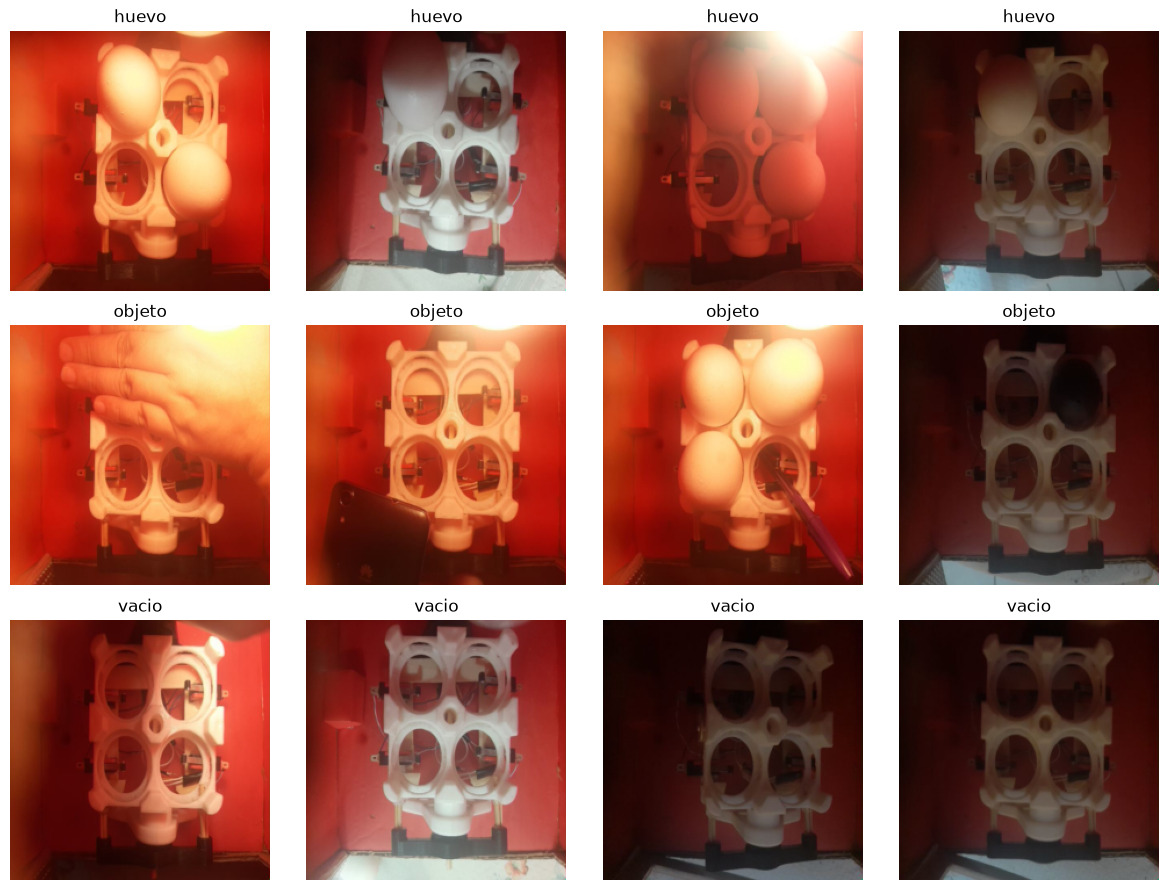

In [3]:
# Ejemplos de cada clase
rng = np.random.default_rng(0)
figure, axes = plt.subplots(len(sv.CLASSES), 4, figsize=(12, 3 * len(sv.CLASSES)))
for row, name in enumerate(sv.CLASSES):
    of_class = [s for s in samples if s.label == row]
    for axis, index in zip(axes[row], rng.choice(len(of_class), size=4, replace=len(of_class) < 4)):
        axis.imshow(sv.load_image(of_class[index].path).permute(1, 2, 0).numpy())
        axis.set_title(name)
        axis.axis("off")
figure.tight_layout()

## 2. Aumento de datos

En cada época, el modelo ve versiones ligeramente distintas de las fotos de entrenamiento. Así aprende a no depender de detalles que pueden cambiar en la incubadora:

- **Brillo, contraste y color** (±30 %): el foco se enciende y se apaga, y la luz del cuarto cambia.
- **Rotación ±6°, desplazamiento ±4 % y zoom ±5 %**: la bandeja se mueve un poco.
- **Espejo horizontal** y **desenfoque leve**.

**No se recorta la imagen**: un objeto en la orilla (escena 10 de `objeto`) debe seguir viéndose. Por la misma razón, la foto completa se estira a 224×224 en vez de recortar el centro.

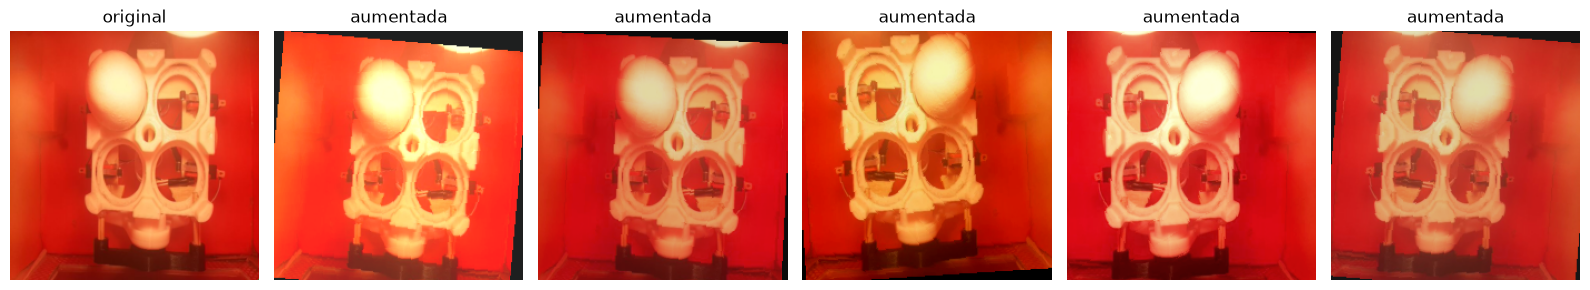

In [4]:
augment = sv.train_transform()
example = sv.load_image(samples[0].path)
figure, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(example.permute(1, 2, 0).numpy())
axes[0].set_title("original")
mean = torch.tensor(sv.IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(sv.IMAGENET_STD).view(3, 1, 1)
for axis in axes[1:]:
    shown = (augment(example) * std + mean).clamp(0, 1)
    axis.imshow(shown.permute(1, 2, 0).numpy())
    axis.set_title("aumentada")
for axis in axes:
    axis.axis("off")
figure.tight_layout()

## 3. Modelo

MobileNetV2 con su clasificador de ImageNet (1000 clases) reemplazado por uno nuevo: `Dropout(0.3) → Linear(1280 → 3)`.

El entrenamiento tiene dos fases:

1. **Cabeza** (lr = 1e-3): la base queda congelada y solo aprende la capa nueva.
2. **Ajuste fino** (lr = 1e-4): se descongelan los últimos 5 bloques para adaptar las características a nuestras fotos.

Se usa `CrossEntropyLoss` con **pesos por clase** (por si las clases no quedan exactamente balanceadas) y *label smoothing* 0.05. En cada fase se guarda la época con **mejor F1 macro en validación**, y el entrenamiento se detiene si pasan 4 épocas sin mejora.

In [5]:
model = sv.build_model(pretrained=True)
total = sum(p.numel() for p in model.parameters())
print(f"Parámetros: {total / 1e6:.2f} M")

Parámetros: 2.23 M


## 4. Validación cruzada

Se entrenan los 5 modelos (uno por partición) y se mide cada uno con su conjunto de prueba.

- **Precision**: de las fotos que el modelo llamó *X*, cuántas eran *X*.
- **Recall**: de las fotos que eran *X*, cuántas encontró.
- **F1**: media armónica de las dos anteriores. El **F1 macro** es el promedio de las tres clases.

La métrica más importante para la seguridad es el **recall de `objeto`**: un objeto no detectado no bloquea el sistema. Un falso positivo, en cambio, se filtra con la regla de 3 de 5 fotos del backend. Se reporta la **media ± desviación estándar** de las 5 particiones.

In [6]:
cv = sv.cross_validate(samples, PARTICIONES, head_epochs=EPOCAS_CABEZA,
                       finetune_epochs=EPOCAS_AJUSTE, device=DEVICE)


=== Partición 1/5 ===
conjunto         huevo  objeto   vacio   total
entrenamiento      169     185     160     514
validación          39      45      40     124
prueba              52      60      50     162


[cabeza] época 1/8  pérdida 1.011  exactitud 0.475  val exactitud 0.532  val F1 0.430  (33 s)


[cabeza] época 2/8  pérdida 0.867  exactitud 0.632  val exactitud 0.831  val F1 0.825  (31 s)


[cabeza] época 3/8  pérdida 0.789  exactitud 0.704  val exactitud 0.815  val F1 0.806  (32 s)


[cabeza] época 4/8  pérdida 0.747  exactitud 0.714  val exactitud 0.855  val F1 0.852  (31 s)


...

[ajuste] época 9/12  pérdida 0.265  exactitud 0.973  val exactitud 0.919  val F1 0.920  (29 s)


[ajuste] época 10/12  pérdida 0.280  exactitud 0.965  val exactitud 0.919  val F1 0.920  (29 s)


[ajuste] época 11/12  pérdida 0.291  exactitud 0.950  val exactitud 0.919  val F1 0.920  (28 s)


[ajuste] sin mejora en 4 épocas; se detiene.


Partición 5: exactitud 0.827  F1 macro 0.814  recall objeto 0.509


métrica                P1     P2     P3     P4     P5   media ± desv.
exactitud           0.870  0.920  0.933  0.910  0.827    0.892 ± 0.039
F1 macro            0.874  0.921  0.934  0.908  0.814    0.890 ± 0.043
recall huevo        1.000  0.865  0.963  1.000  1.000    0.966 ± 0.052
recall objeto       0.717  0.900  0.850  0.745  0.509    0.744 ± 0.135
recall vacio        0.920  1.000  1.000  1.000  1.000    0.984 ± 0.032
precisión objeto    0.915  0.885  0.962  1.000  1.000    0.952 ± 0.046


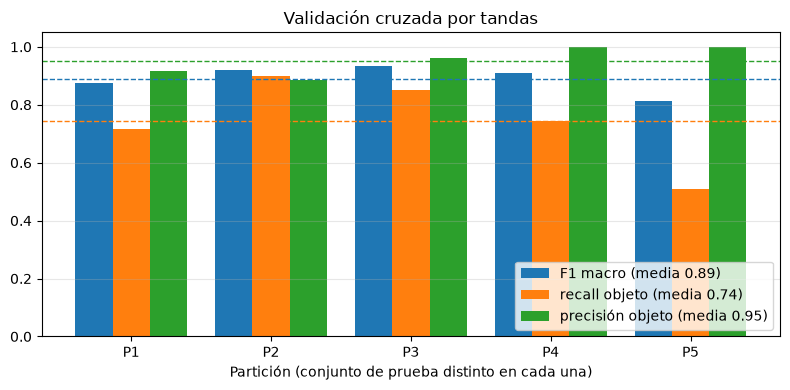

In [7]:
print(sv.summarize_cv(cv))
sv.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
sv.plot_cross_validation(cv, sv.RESULTS_DIR / "validacion_cruzada.png");

### Resultado global

Las predicciones de prueba de las 5 particiones juntas: cada una de las fotos del dataset aparece una vez, predicha por el modelo que no la vio.

              precision    recall  f1-score   support

       huevo      0.857     0.965     0.908       260
      objeto      0.943     0.748     0.835       290
       vacio      0.888     0.984     0.934       250

    accuracy                          0.892       800
   macro avg      0.896     0.899     0.892       800
weighted avg      0.898     0.892     0.889       800



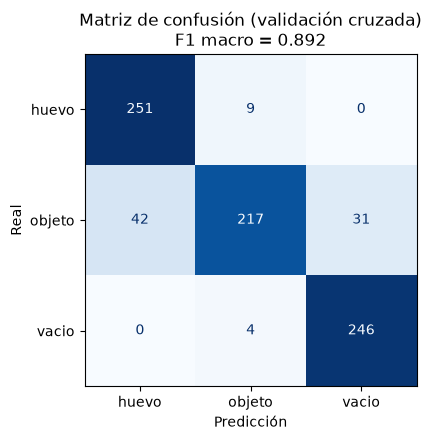

In [8]:
print(cv["global"]["reporte"])
sv.plot_confusion(cv["global"], sv.RESULTS_DIR / "matriz_confusion.png",
                  title="Matriz de confusión (validación cruzada)");

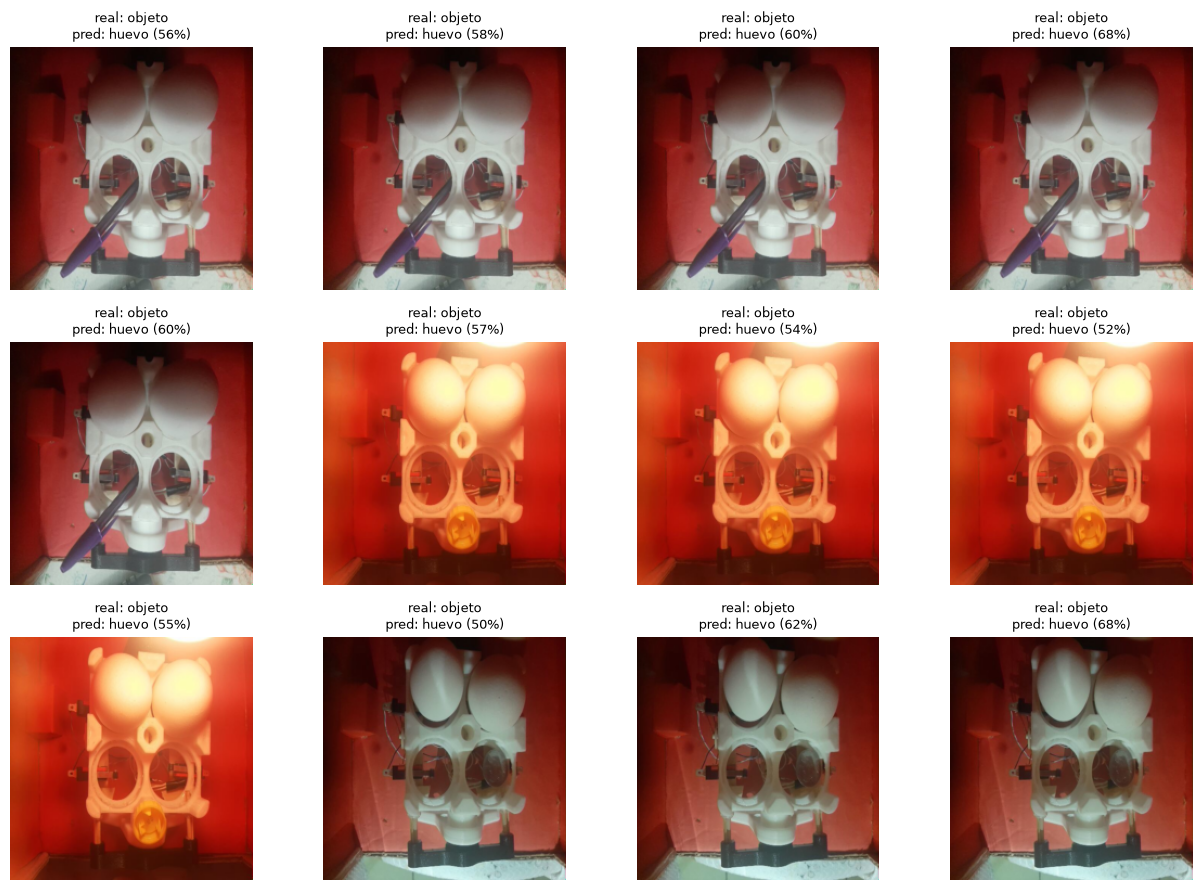

In [9]:
# Fotos mal clasificadas (las primeras 12)
figure = sv.plot_errors(cv["samples"], cv["labels"], cv["probabilidades"], sv.RESULTS_DIR / "errores.png")
if figure is None:
    print("No hubo errores.")

### Análisis

**Resultado (validación cruzada, 5 particiones, 800 fotos):** exactitud **0.89 ± 0.04** y F1 macro **0.89 ± 0.04**.

| Clase | Recall (media ± desv.) | Lectura |
|---|---|---|
| `huevo` | 0.97 ± 0.05 | casi nunca se confunde |
| `vacio` | 0.98 ± 0.03 | casi nunca se confunde |
| `objeto` | **0.74 ± 0.14** | es la clase difícil; varía de 0.51 a 0.90 según qué tandas caen en prueba |

**Falsas alarmas:** cuando el modelo dice `objeto`, acierta el 95 % de las veces. Solo 13 de las 510 fotos de `huevo` y `vacio` se marcaron como `objeto` (2.5 %).

**Dónde falla (ver la matriz y las fotos):**

- **Objeto → huevo (42 fotos):** objetos delgados o pequeños junto a huevos, como un lapicero cruzado sobre la bandeja o una tapita bajo la luz roja del foco. Al reducir la foto a 224×224 el objeto ocupa muy poca área y domina la forma de los huevos.
- **Objeto → vacío (31 fotos):** objetos oscuros en penumbra y sin huevos, que se pierden con el fondo.
- Los errores vienen **por tandas completas**: si una escena es difícil, falla en sus 5 fotos. La regla de 3 de 5 fotos del backend elimina las falsas alarmas aisladas, pero no recupera un objeto que el modelo no ve en ninguna foto de la escena.

**Por qué varía tanto entre particiones:** hay unas 60 tandas de `objeto`, así que cada prueba tiene unas 12. Una o dos escenas difíciles mueven el recall hasta 20 puntos. Por eso se reporta la media de 5 particiones y no una sola división.

**Mejoras posibles:** más tandas de objetos delgados y oscuros con poca luz, y clasificar cada uno de los 4 espacios de la bandeja por separado (recortes de mayor resolución) en lugar de la foto completa.

## 5. Modelo final

La validación cruzada mide qué tan bien funciona el método. El modelo que se exporta se entrena **con todas las fotos**, para que haya visto todos los casos difíciles. Solo se aparta un 15 % (por tandas) como validación, para elegir la mejor época; no hay conjunto de prueba porque su rendimiento esperado es el de la validación cruzada.

In [10]:
sv.set_seed()
final_split = sv.split_by_group(samples, test_ratio=0)
print(sv.describe_split(final_split))
train_loader, val_loader, _ = sv.make_loaders(final_split)
model = sv.build_model(pretrained=True)
history = sv.train(model, train_loader, val_loader, sv.class_weights(final_split.train),
                   head_epochs=EPOCAS_CABEZA, finetune_epochs=EPOCAS_AJUSTE, device=DEVICE)

conjunto         huevo  objeto   vacio   total
entrenamiento      220     245     210     675
validación          40      45      40     125
prueba               0       0       0       0


[cabeza] época 1/8  pérdida 1.003  exactitud 0.527  val exactitud 0.624  val F1 0.528  (30 s)


[cabeza] época 2/8  pérdida 0.808  exactitud 0.674  val exactitud 0.648  val F1 0.611  (29 s)


[cabeza] época 3/8  pérdida 0.744  exactitud 0.721  val exactitud 0.672  val F1 0.625  (32 s)


[cabeza] época 4/8  pérdida 0.690  exactitud 0.761  val exactitud 0.680  val F1 0.631  (30 s)


...

[ajuste] época 8/12  pérdida 0.296  exactitud 0.960  val exactitud 0.864  val F1 0.859  (36 s)


[ajuste] época 9/12  pérdida 0.302  exactitud 0.945  val exactitud 0.872  val F1 0.868  (36 s)


[ajuste] época 10/12  pérdida 0.297  exactitud 0.957  val exactitud 0.880  val F1 0.877  (36 s)


[ajuste] época 11/12  pérdida 0.285  exactitud 0.966  val exactitud 0.880  val F1 0.877  (36 s)


[ajuste] época 12/12  pérdida 0.290  exactitud 0.961  val exactitud 0.888  val F1 0.885  (37 s)


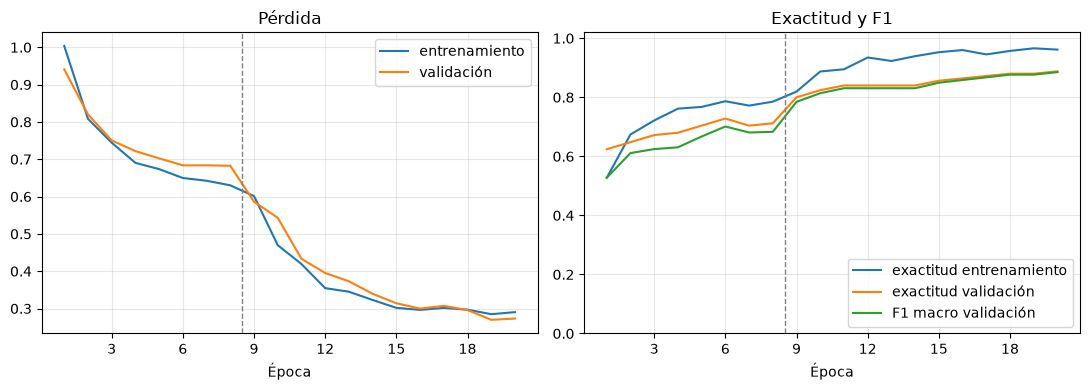

In [11]:
sv.plot_history(history, sv.RESULTS_DIR / "curvas_entrenamiento.png");

## 6. Exportación a ONNX

El modelo final se exporta a **ONNX** con la normalización y el `softmax` incluidos. El servicio de visión en Docker solo necesita **OpenCV** (`cv2.dnn`), sin PyTorch, y su imagen queda liviana.

- Entrada `imagen`: `1×3×224×224`, RGB, valores 0-255 (lo que entrega `cv2.dnn.blobFromImage(bgr, 1.0, (224, 224), swapRB=True)`).
- Salida `probabilidades`: `1×3`, en el orden de `clases.json`.

Al final se comprueba que OpenCV y PyTorch dan el mismo resultado.

In [12]:
onnx_path = sv.export_onnx(model)
difference = sv.verify_onnx(model, onnx_path, final_split.val[:10])
sv.save_results(cv, history, final_split)
print(f"Modelo: {onnx_path} ({onnx_path.stat().st_size / 1e6:.1f} MB)")
print(f"Diferencia máxima PyTorch vs OpenCV: {difference:.2e}")
print(f"Resultados en: {sv.RESULTS_DIR}")

Modelo: /mnt/development/Proyectos/AYC2_G3/Proyecto_2_SmartEgg/ml/vision/modelo/smartegg_vision.onnx (9.2 MB)
Diferencia máxima PyTorch vs OpenCV: 3.43e-06
Resultados en: /mnt/development/Proyectos/AYC2_G3/Proyecto_2_SmartEgg/ml/vision/resultados


## 7. Uso en el servicio de visión

```python
import cv2
net = cv2.dnn.readNetFromONNX("modelo/smartegg_vision.onnx")
blob = cv2.dnn.blobFromImage(foto_bgr, 1.0, (224, 224), swapRB=True, crop=False)
net.setInput(blob)
probabilidades = net.forward()[0]   # [huevo, objeto, vacio]
```

El servicio publica cada resultado en `smartegg/node-1/vision/result`. El backend bloquea el sistema (`system/lock`) cuando **3 de las últimas 5 fotos** salen como `objeto`, para no bloquear por un error aislado.

Para probar el modelo desde la terminal: `python ml/vision/predecir.py dataset/objeto`.